In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import optuna
import pandas as pd
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

project_root = Path.cwd().resolve()
if not (project_root / 'src').exists():
    project_root = project_root.parent

sys.path.insert(0, str(project_root))

from src.data import build_preprocessor, set_categorical_features
from src.features import (
    add_family_group,
    add_family_size,
    add_features,
    add_is_child,
    add_title,
    extract_title,
)
from src.nn import cross_validate_mlp, fit_mlp

optuna.logging.set_verbosity(optuna.logging.WARNING)

In [2]:
RANDOM_STATE = 42

cv = StratifiedKFold(n_splits=5, random_state=RANDOM_STATE, shuffle=True)

In [3]:
def cv_accuracy(model, X, y, n_jobs=None, **fit_params):
    """Return per-fold accuracy of the model on the shared stratified 5-fold split.

    LightGBM segfaults in parallel workers on macOS, so folds run sequentially by default.
    """
    return cross_val_score(
        model, X, y,
        cv=cv,
        scoring='accuracy',
        params=fit_params or None,
        n_jobs=n_jobs,
        error_score='raise',
    )


def evaluate_features(X, y, num_features, cat_features):
    """Print and return CV accuracy of logistic regression on the given feature set."""
    model = Pipeline([
        ('preprocessing', build_preprocessor(num_features, cat_features)),
        ('lr', LogisticRegression()),
    ])
    scores = cv_accuracy(model, X, y)
    print(f'CV accuracy: {scores.mean():.4f} ± {scores.std():.4f}')
    return scores


def run_study(objective, study_name, n_trials=50):
    """Maximize the objective with a seeded TPE sampler and print the best result."""
    study = optuna.create_study(
        study_name=study_name,
        direction='maximize',
        sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
    )
    study.optimize(objective, n_trials=n_trials)

    print(f'Best CV accuracy: {study.best_value:.4f}')
    print(f'Best params: {study.best_params}')
    return study

# Загрузка данных

In [4]:
train_data = pd.read_csv(project_root / 'input_files/train.csv')
test_data = pd.read_csv(project_root / 'input_files/test.csv')

y_train = train_data['Survived']

# Бейзлайн

In [5]:
train_data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


берем признаки Pclass, Sex, Age, SibSp, Parch, Fare, Embarked

In [6]:
num_features = ['Age', 'SibSp', 'Parch', 'Fare']
cat_features = ['Sex', 'Pclass', 'Embarked']

baseline_scores = evaluate_features(train_data, y_train, num_features, cat_features)

CV accuracy: 0.7969 ± 0.0146


Сравним с классификатором, который предсказывает самый частый класс

In [7]:
dummy_scores = cv_accuracy(DummyClassifier(strategy='most_frequent'), train_data, y_train)

print(f'Dummy accuracy: {dummy_scores.mean():.4f}')

Dummy accuracy: 0.6162


# Эксперименты с применением feature engineering

### E1: исходные фичи + IsChild

In [8]:
X_exp = add_is_child(train_data)

num_features = ['Age', 'SibSp', 'Parch', 'Fare', 'IsChild']
cat_features = ['Sex', 'Pclass', 'Embarked']

evaluate_features(X_exp, y_train, num_features, cat_features);

CV accuracy: 0.8103 ± 0.0090


### E2: объединяем SibSp и Parch в FamilySize

In [9]:
X_exp = add_family_size(train_data)

num_features = ['Age', 'Fare', 'FamilySize']
cat_features = ['Sex', 'Pclass', 'Embarked']

evaluate_features(X_exp, y_train, num_features, cat_features);

CV accuracy: 0.8013 ± 0.0109


### E3: исходные + IsAlone

In [10]:
X_exp = train_data.assign(IsAlone=(train_data['SibSp'] + train_data['Parch'] == 0).astype(int))

num_features = ['Age', 'Fare', 'Parch', 'SibSp', 'IsAlone']
cat_features = ['Sex', 'Pclass', 'Embarked']

evaluate_features(X_exp, y_train, num_features, cat_features);

CV accuracy: 0.7991 ± 0.0183


### E4: + размер семьи (малый, средний, большой)

In [11]:
X_exp = add_family_group(train_data)

num_features = ['Age', 'Fare']
cat_features = ['Sex', 'Pclass', 'Embarked', 'FamilyGroup']

evaluate_features(X_exp, y_train, num_features, cat_features);

CV accuracy: 0.8115 ± 0.0114


### E5: извлекаем титул из имени

In [12]:
extract_title(train_data['Name']).value_counts()

0
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Major             2
Mlle              2
Col               2
Don               1
Mme               1
Ms                1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Name: count, dtype: int64

In [13]:
X_exp = add_title(train_data)

num_features = ['Age', 'Fare', 'SibSp', 'Parch']
cat_features = ['Sex', 'Pclass', 'Title', 'Embarked']

evaluate_features(X_exp, y_train, num_features, cat_features);

CV accuracy: 0.8283 ± 0.0131


### E6: Title + IsChild

In [14]:
X_exp = add_is_child(add_title(train_data))

num_features = ['Age', 'Fare', 'SibSp', 'Parch', 'IsChild']
cat_features = ['Sex', 'Pclass', 'Title', 'Embarked']

evaluate_features(X_exp, y_train, num_features, cat_features);

CV accuracy: 0.8272 ± 0.0090


одновременное использование Title и IsChild не улучшает метрику. Это я бы объяснил тем, что Title уже содержит в себе информацию о том, ребенок это или нет (класс Master -- обращение к мальчику)

### E7: Title + FamilyGroup

In [15]:
X_exp = add_family_group(add_title(train_data))

num_features = ['Age', 'Fare']
cat_features = ['Sex', 'Pclass', 'Title', 'Embarked', 'FamilyGroup']

evaluate_features(X_exp, y_train, num_features, cat_features);

CV accuracy: 0.8283 ± 0.0112


### E8: добавим признак HasCabin

In [16]:
X_exp = add_features(train_data)

num_features = ['Age', 'Fare', 'SibSp', 'Parch']
cat_features = ['Sex', 'Pclass', 'Title', 'Embarked', 'FamilyGroup', 'HasCabin']

evaluate_features(X_exp, y_train, num_features, cat_features);

CV accuracy: 0.8305 ± 0.0069


лучший результат

# Модели

In [17]:
num_features = ['Age', 'Fare', 'SibSp', 'Parch', 'HasCabin']
cat_features = ['Sex', 'Pclass', 'Title', 'Embarked', 'FamilyGroup']

X_model = add_features(train_data)[num_features + cat_features]
X_boost = set_categorical_features(X_model, cat_features)

## LightGBM

In [18]:
def objective_lgbm(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 1000),
        'max_depth': trial.suggest_int('max_depth', 2, 10),
        'num_leaves': trial.suggest_int('num_leaves', 2, 31),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 40),
    }
    model = LGBMClassifier(**params, random_state=RANDOM_STATE, verbosity=-1)
    return cv_accuracy(model, X_boost, y_train).mean()


study_lgbm = run_study(objective_lgbm, 'LGBM hyperparameters search')

Best CV accuracy: 0.8507
Best params: {'n_estimators': 639, 'max_depth': 2, 'num_leaves': 13, 'learning_rate': 0.08285256787861559, 'min_child_samples': 18}


## XGBoost

In [19]:
def objective_xgb(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 1000),
        'max_depth': trial.suggest_int('max_depth', 2, 8),
        'min_child_weight': trial.suggest_float('min_child_weight', 1, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
    }
    model = XGBClassifier(
        **params,
        random_state=RANDOM_STATE,
        eval_metric='logloss',
        enable_categorical=True,
    )
    return cv_accuracy(model, X_boost, y_train, n_jobs=-1).mean()


study_xgb = run_study(objective_xgb, 'XGB hyperparameters search')

Best CV accuracy: 0.8519
Best params: {'n_estimators': 852, 'max_depth': 7, 'min_child_weight': 8.17845555951574, 'learning_rate': 0.03471243117381785, 'subsample': 0.7319171874889909}


## CatBoost

In [20]:
X_cb = X_model.copy()
X_cb[cat_features] = X_cb[cat_features].astype('string').fillna('Missing')

cb_params = {'random_state': RANDOM_STATE, 'verbose': 0, 'allow_writing_files': False}

In [21]:
cb_scores = cv_accuracy(
    CatBoostClassifier(**cb_params), X_cb, y_train, n_jobs=-1, cat_features=cat_features
)

print(f'CV accuracy: {cb_scores.mean():.4f} ± {cb_scores.std():.4f}')

CV accuracy: 0.8294 ± 0.0182


In [22]:
def objective_catboost(trial):
    params = {
        'iterations': trial.suggest_int('iterations', 200, 1000),
        'depth': trial.suggest_int('depth', 2, 8),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'l2_leaf_reg': trial.suggest_int('l2_leaf_reg', 1, 10, log=True),
        'random_strength': trial.suggest_float('random_strength', 0.0, 2.0),
    }
    model = CatBoostClassifier(**params, **cb_params)
    return cv_accuracy(model, X_cb, y_train, n_jobs=-1, cat_features=cat_features).mean()


study_cb = run_study(objective_catboost, 'CatBoost hyperparameters search')

Best CV accuracy: 0.8451
Best params: {'iterations': 969, 'depth': 4, 'learning_rate': 0.046991733314351435, 'l2_leaf_reg': 1, 'random_strength': 1.976144197516792}


## MLP

### Кривые обучения на одном разбиении

In [23]:
X_tr, X_val, y_tr, y_val = train_test_split(
    X_model, y_train, test_size=0.2, stratify=y_train, random_state=RANDOM_STATE
)

preprocessor = build_preprocessor(num_features, cat_features)
X_tr = preprocessor.fit_transform(X_tr)
X_val = preprocessor.transform(X_val)

model_nn, history = fit_mlp(X_tr, y_tr, X_val, y_val, random_state=RANDOM_STATE)

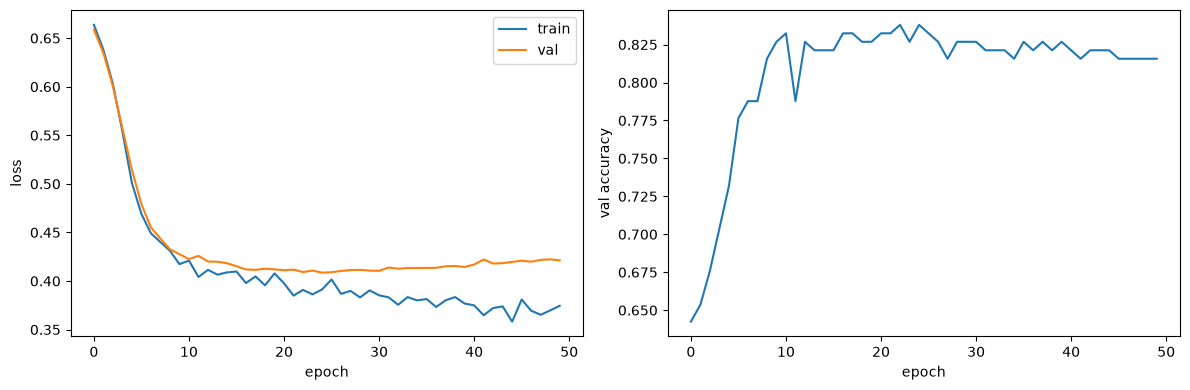

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history['train_loss'], label='train')
axes[0].plot(history['val_loss'], label='val')
axes[0].set_xlabel('epoch')
axes[0].set_ylabel('loss')
axes[0].legend()

axes[1].plot(history['val_acc'])
axes[1].set_xlabel('epoch')
axes[1].set_ylabel('val accuracy')

plt.tight_layout()
plt.show()

### AIPX_ffdfa313_0050-валидация

In [25]:
mlp_scores = cross_validate_mlp(
    X_model, y_train,
    num_features, cat_features,
    cv=cv,
    random_state=RANDOM_STATE,
)

print(f'CV accuracy: {mlp_scores.mean():.4f} ± {mlp_scores.std():.4f}')

CV accuracy: 0.8327 ± 0.0128
